# Feature Importance and Model Interpretation

This notebook evaluates model explainability using coefficients, permutation importance on the untouched temporal test set, and native tree importances.

> 📌 **Orchestration Note:** Reusable explainability functions live in `icare_risk.explainability`.

> 📌 **Orchestration Note:** Feature selection for parsimonious models must always be performed using development data only.

In [15]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Setup and Environment Configuration

We load the configuration, ingest the processed dataset, isolate the held-out temporal test set, and load all saved model bundles into memory.

In [2]:
from pathlib import Path
import joblib
import pandas as pd
import yaml
from IPython.display import display

from icare_risk.data.audit import load_admission_file
from icare_risk.models.training import encode_binary_target
from icare_risk.explainability import (
    model_coefficients,
    native_tree_importance,
    permutation_importance_table,
)

# Load configuration
CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

# Load dataset and encode binary target for test evaluation
df = load_admission_file(config['outputs']['processed_dataset'])
target = config['columns']['target']
test = df.loc[df['split'].eq('test')].copy()
target_mapping = config.get('target_mapping', {})
test['__binary_target__'] = encode_binary_target(
    test[target],
    positive_values=target_mapping.get('positive_values'),
    negative_values=target_mapping.get('negative_values'),
)
test = test.dropna(subset=['__binary_target__'])
y_test = test['__binary_target__'].astype(int)
print(f'Test admissions with known outcomes: {len(test):,}')
print(f'Events: {y_test.sum():,}; event rate: {y_test.mean():.3f}')


# Load saved model bundles
model_directory = Path(config['outputs']['model_directory'])
fitted_models = {}
feature_map = {}
for model_cfg in config['models']:
    name = model_cfg['name']
    bundle = joblib.load(model_directory / f'{name}.joblib')
    fitted_models[name] = bundle['model']
    feature_map[name] = bundle['features']

available_models = list(fitted_models)
print('Available models:')
for m in available_models:
    print(f"    - {m}")

Test admissions with known outcomes: 2,483
Events: 493; event rate: 0.199
Available models:
    - lr_kim_components
    - lr_all_score_values
    - lr_clinical_baseline
    - xgb_kim_components
    - xgb_all_score_values
    - xgb_clinical_baseline


## 2. Logistic Regression Coefficients and Odds Ratios

For linear models, we extract coefficients and compute odds ratios to quantify the directional impact of each transformed feature on predicted risk.

In [4]:
coefficient_tables = []
for name, model in fitted_models.items():
    if hasattr(model.named_steps.get('classifier'), 'coef_'):
        coefficient_tables.append(model_coefficients(model, model_name=name))

coefficients = (
    pd.concat(coefficient_tables, ignore_index=True)
    if coefficient_tables
    else pd.DataFrame()
)
display(coefficients.head(15))

,model,feature,coefficient,odds_ratio,absolute_coefficient
0,lr_kim_components,numeric__kim_hx_prior_antibiotics_90d,0.175660,1.192033,0.175660
1,lr_kim_components,numeric__kim_hx_prior_esbl,-0.048014,0.953120,0.048014
2,lr_kim_components,numeric__kim_hx_recent_hosp_1yr,0.000000,1.000000,0.000000
3,lr_kim_components,numeric__kim_hx_nursing_home_resident,0.000000,1.000000,0.000000
4,lr_kim_components,numeric__kim_hx_urinary_catheter,0.000000,1.000000,0.000000
5,lr_all_score_values,numeric__tumbarello_score,0.172594,1.188383,0.172594
6,lr_all_score_values,numeric__kim_score,-0.147193,0.863127,0.147193
7,lr_all_score_values,numeric__jones_score,-0.032482,0.968040,0.032482
8,lr_all_score_values,numeric__charlson_score,0.005917,1.005934,0.005917
9,lr_all_score_values,numeric__gavaghan_score,0.000000,1.000000,0.000000


## 3. Permutation and Native Tree Importance

We calculate held-out permutation importance across all models to measure feature impact on test set predictive performance ($ROC-AUC$). For tree models, we also extract native feature importances.

In [5]:
permutation_tables = []
native_tables = []
n_repeats = config.get('explainability', {}).get('permutation_repeats', 20)

for name, model in fitted_models.items():
    features = feature_map[name]
    X_test = test[features]
    permutation_tables.append(
        permutation_importance_table(
            model, X_test, y_test, model_name=name,
            n_repeats=n_repeats,
        )
    )
    classifier = model.named_steps['classifier']
    if hasattr(classifier, 'feature_importances_'):
        native_tables.append(native_tree_importance(model, model_name=name))

permutation_importance = pd.concat(permutation_tables, ignore_index=True)
native_importance = (
    pd.concat(native_tables, ignore_index=True)
    if native_tables
    else pd.DataFrame()
)

output_directory = Path(config['outputs']['feature_importance_directory'])
output_directory.mkdir(parents=True, exist_ok=True)

if not coefficients.empty:
    coefficients.to_csv(output_directory / 'logistic_regression_coefficients.csv', index=False)
permutation_importance.to_csv(output_directory / 'permutation_importance.csv', index=False)
if not native_importance.empty:
    native_importance.to_csv(output_directory / 'native_tree_importance.csv', index=False)


print(f'Successfully saved feature-importance results to {output_directory}')
display(permutation_importance.head(15))

Successfully saved feature-importance results to results/feature_importance


,model,feature,importance_mean,importance_std,importance_rank
0,lr_kim_components,kim_hx_prior_antibiotics_90d,0.000347,0.007755,1
1,lr_kim_components,kim_hx_nursing_home_resident,0.000000,0.000000,2
2,lr_kim_components,kim_hx_recent_hosp_1yr,0.000000,0.000000,3
3,lr_kim_components,kim_hx_urinary_catheter,0.000000,0.000000,4
4,lr_kim_components,kim_hx_prior_esbl,-0.001125,0.000902,5
5,lr_all_score_values,charlson_score,0.011300,0.009731,1
6,lr_all_score_values,tumbarello_score,0.003864,0.009361,2
7,lr_all_score_values,holmgren_score,0.000000,0.000000,3
8,lr_all_score_values,gavaghan_score,0.000000,0.000000,4
9,lr_all_score_values,jones_score,-0.000164,0.004206,5


## 4. Visualizing Feature Importance

To support model auditing and clinical review, we load the saved `.csv` artifacts back from disk to plot the top feature importances for key models.

#### How to Interpret the Graphs:
* **Permutation Importance (Left):** Measures the drop in model evaluation metric ($ROC-AUC$) when a feature's values are randomly shuffled. Larger positive values indicate features the model heavily relies on for generalisation.
* **Model Coefficients / Native Importance (Right):** Displays the internal magnitude and direction of feature weights (for linear models) or Gini/split importance (for tree models).

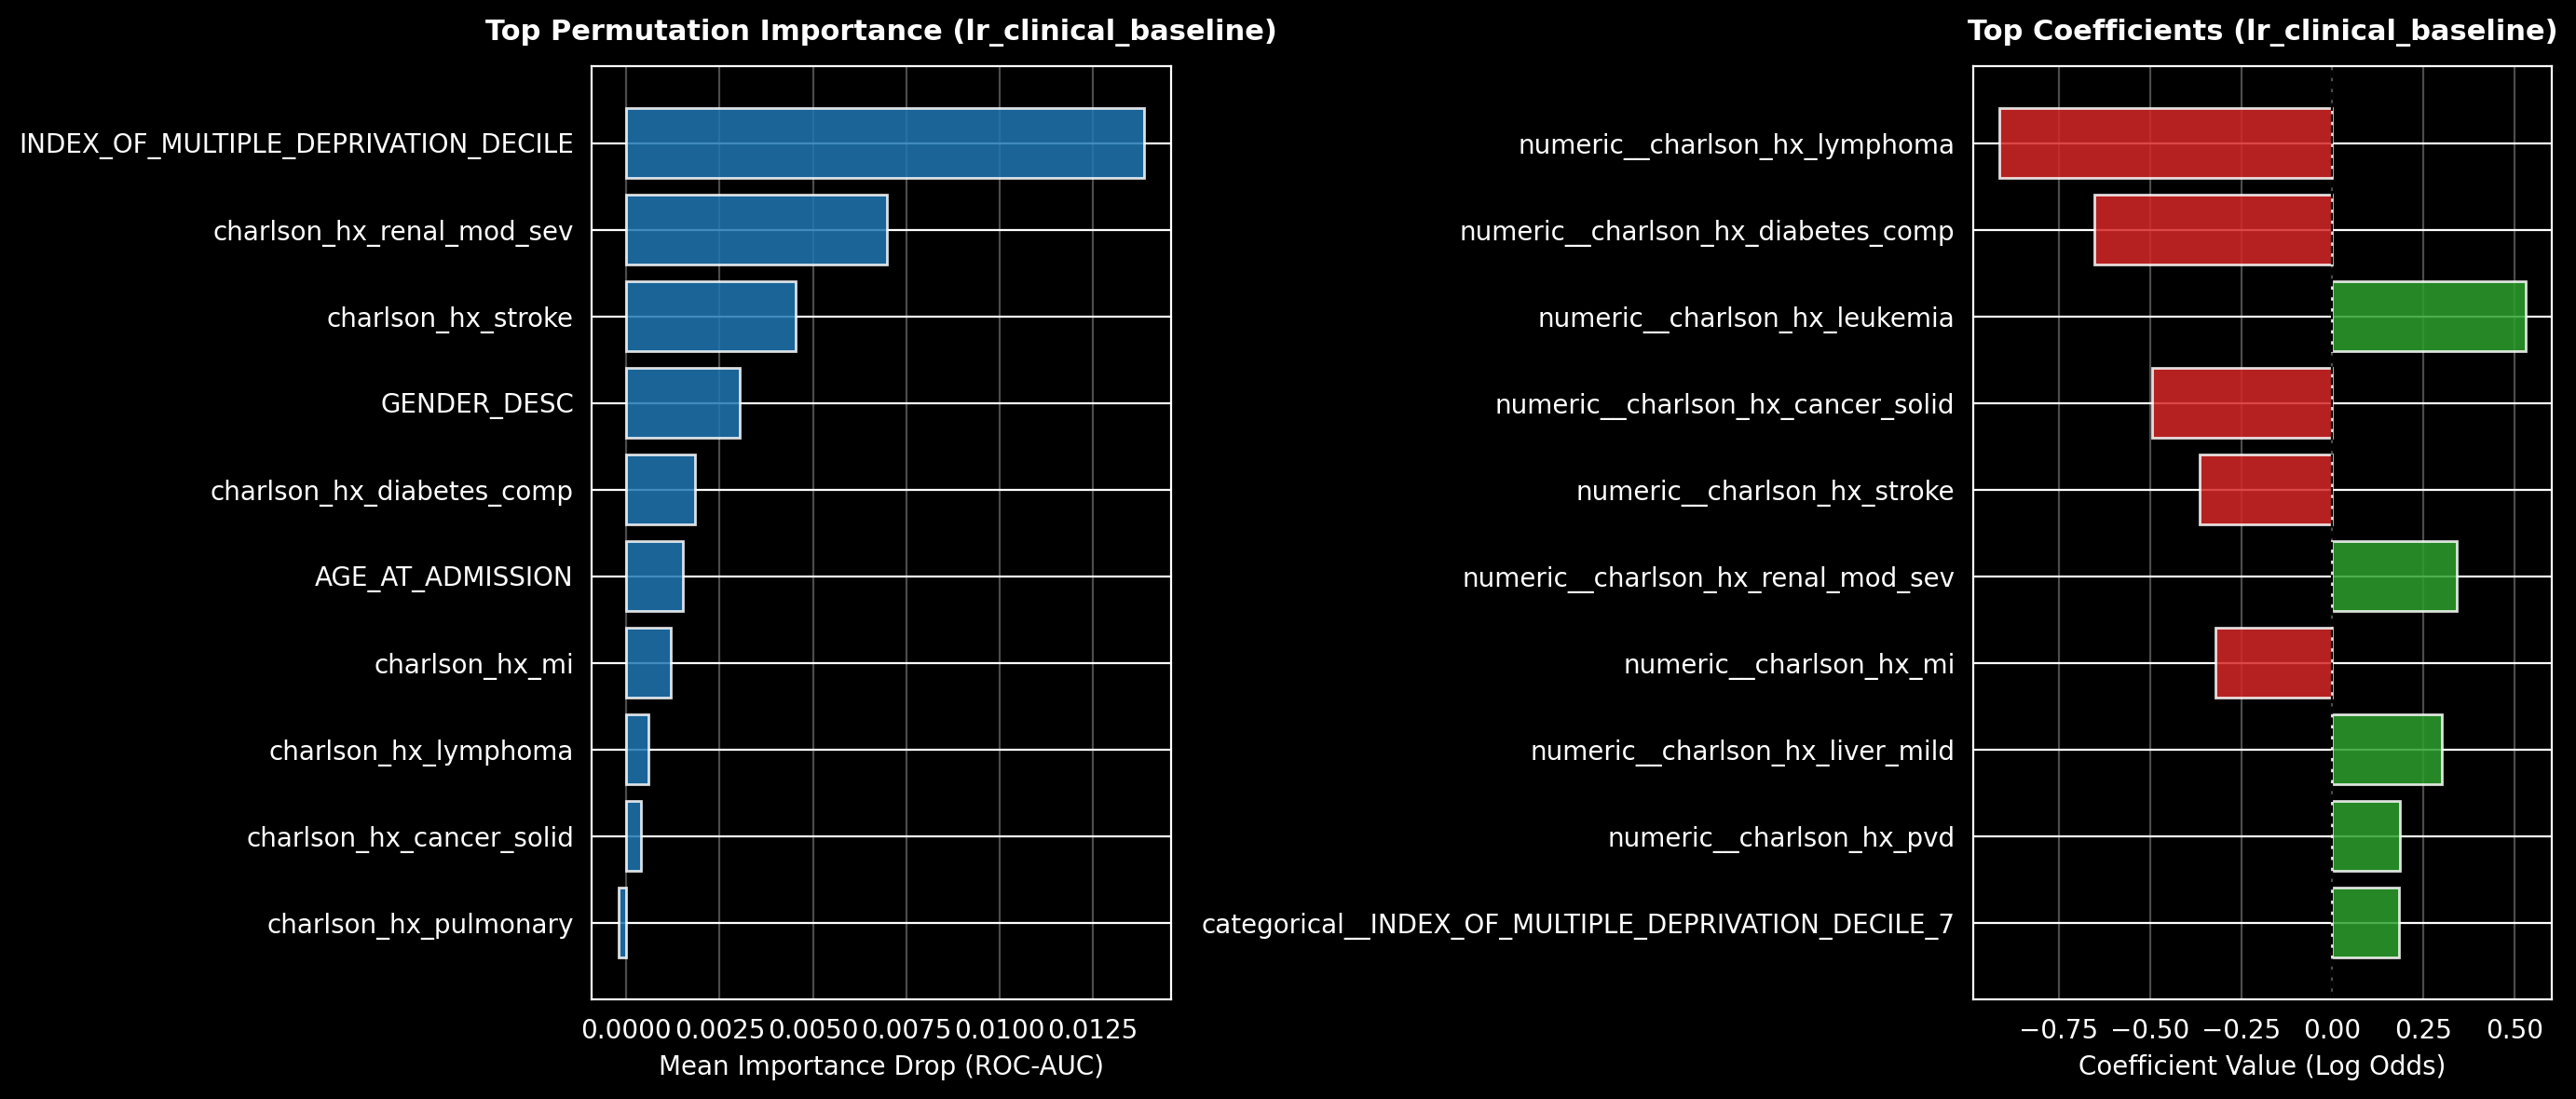

Successfully reloaded CSV data and saved visualization plots to results/feature_importance/feature_importance_plots.png


In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Load data back from CSV storage
perm_df = pd.read_csv(output_directory / 'permutation_importance.csv')
coef_df = pd.read_csv(output_directory / 'logistic_regression_coefficients.csv')

# Set up dual subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=200)

# --- Plot 1: Top Permutation Importances for Clinical Baseline ---
sample_model = 'lr_clinical_baseline'
subset_perm = perm_df[perm_df['model'] == sample_model].head(10).sort_values('importance_mean', ascending=True)

if not subset_perm.empty:
    ax1.barh(subset_perm['feature'], subset_perm['importance_mean'], color='#1f77b4', alpha=0.85)
    ax1.set_title(f"Top Permutation Importance ({sample_model})", fontsize=11, fontweight="bold", pad=10)
    ax1.set_xlabel("Mean Importance Drop (ROC-AUC)", fontsize=10)
    ax1.grid(axis='x', alpha=0.3)

# --- Plot 2: Top Logistic Coefficients ---
subset_coef = coef_df[coef_df['model'] == sample_model].head(10).sort_values('absolute_coefficient', ascending=True)

if not subset_coef.empty:
    colors = ['#d62728' if c < 0 else '#2ca02c' for c in subset_coef['coefficient']]
    ax2.barh(subset_coef['feature'], subset_coef['coefficient'], color=colors, alpha=0.85)
    ax2.set_title(f"Top Coefficients ({sample_model})", fontsize=11, fontweight="bold", pad=10)
    ax2.set_xlabel("Coefficient Value (Log Odds)", fontsize=10)
    ax2.grid(axis='x', alpha=0.3)
    ax2.axvline(0, color='black', linewidth=0.8, linestyle='--')

# Save high-resolution figure artifact
plot_path = output_directory / 'feature_importance_plots.png'
fig.savefig(plot_path, dpi=200, bbox_inches='tight')

plt.tight_layout()
plt.show()

print(f'Successfully reloaded CSV data and saved visualization plots to {plot_path}')